<a href="https://colab.research.google.com/github/ompatel420/FreeCodeCamp-Machine-Learning-Project/blob/main/Cat_and_Dog_Image_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Cat_and_Dog_Image_Classifier Project**

In [1]:
try:
    %tensorflow_version 2.x
except Exception:
    pass

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Conv2D, Flatten, Dropout, MaxPooling2D
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input

import os
import numpy as np
import matplotlib.pyplot as plt

Colab only includes TensorFlow 2.x; %tensorflow_version has no effect.


In [4]:
# Download dataset using wget
!wget -O cats_and_dogs.zip https://cdn.freecodecamp.org/project-data/cats-and-dogs/cats_and_dogs.zip

# Extract dataset
!unzip -o cats_and_dogs.zip

# Set dataset paths
PATH = '/content/cats_and_dogs'

train_dir = os.path.join(PATH, 'train')
validation_dir = os.path.join(PATH, 'validation')
test_dir = os.path.join(PATH, 'test')

# Count images
total_train = sum(
    len(files) for r, d, files in os.walk(train_dir)
)

total_val = sum(
    len(files) for r, d, files in os.walk(validation_dir)
)

total_test = len(os.listdir(test_dir))

# Training parameters
batch_size = 128
epochs = 15

IMG_HEIGHT = 150
IMG_WIDTH = 150

print("Training images:", total_train)
print("Validation images:", total_val)
print("Testing images:", total_test)

Streaming output truncated to the last 5000 lines.
  inflating: cats_and_dogs/train/dogs/dog.680.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.680.jpg  
  inflating: cats_and_dogs/train/dogs/dog.694.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.694.jpg  
  inflating: cats_and_dogs/train/dogs/dog.864.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.864.jpg  
  inflating: cats_and_dogs/train/dogs/dog.870.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.870.jpg  
  inflating: cats_and_dogs/train/dogs/dog.871.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.871.jpg  
  inflating: cats_and_dogs/train/dogs/dog.865.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.865.jpg  
  inflating: cats_and_dogs/train/dogs/dog.695.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.695.jpg  
  inflating: cats_and_dogs/train/dogs/dog.681.jpg  
  inflating: __MACOSX/cats_and_dogs/train/dogs/._dog.681.jpg  
  inflating: cats_and_dogs/tr

In [14]:
# Import MobileNetV2 preprocessing
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Image size and batch size
IMG_HEIGHT = 160
IMG_WIDTH = 160
batch_size = 32

# Training image generator
train_image_generator = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation image generator
validation_image_generator = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Test image generator
test_image_generator = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Training data
train_data_gen = train_image_generator.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=batch_size,
    class_mode='binary'
)

# Validation data
val_data_gen = validation_image_generator.flow_from_directory(
    validation_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

# Test data
test_data_gen = test_image_generator.flow_from_directory(
    PATH,
    classes=['test'],
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=batch_size,
    class_mode=None,
    shuffle=False
)

print("Class labels:", train_data_gen.class_indices)

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 50 images belonging to 1 classes.
Class labels: {'cats': 0, 'dogs': 1}


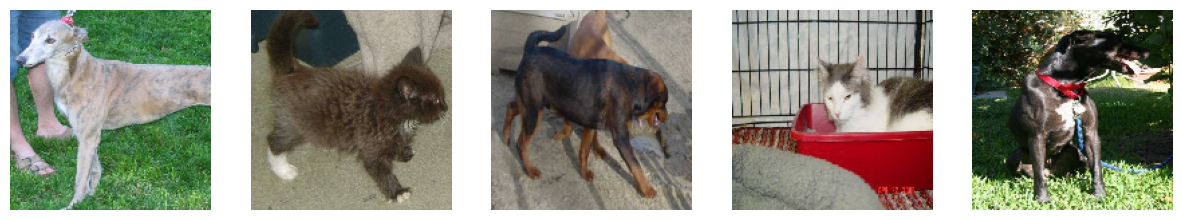

In [6]:
def plotImages(images_arr, probabilities=False):

    fig, axes = plt.subplots(1, 5, figsize=(15, 5))

    for i, ax in enumerate(axes):
        ax.imshow(images_arr[i])

        ax.axis('off')

        if probabilities is not False:
            ax.set_title(
                "{:.0f}% Cat".format(100 * (1 - probabilities[i]))
                if probabilities[i] <= 0.5
                else "{:.0f}% Dog".format(100 * probabilities[i])
            )

    plt.show()


# Get five training images
sample_training_images, _ = next(train_data_gen)

# Display images
plotImages(sample_training_images[:5])

In [7]:
train_image_generator = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

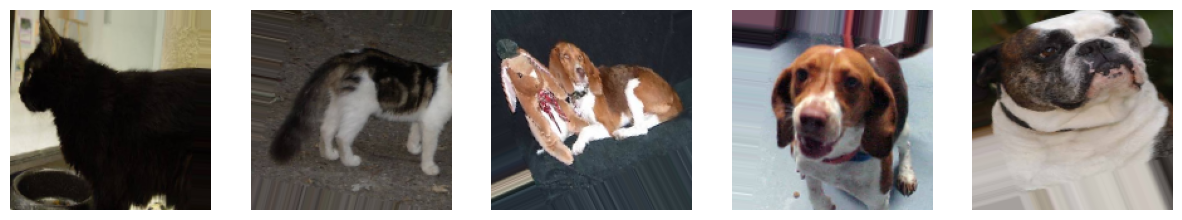

In [15]:
# Load augmented images
augmented_images, _ = next(train_data_gen)

# Convert images back to displayable RGB values
display_images = (augmented_images[:5] + 1) / 2

# Display images
plotImages(display_images)

In [16]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.models import Sequential

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze pretrained layers initially
base_model.trainable = False

# Create classification model
model = Sequential([
    Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    base_model,

    GlobalAveragePooling2D(),

    Dropout(0.3),

    Dense(128, activation='relu'),

    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

# Train the classification layers
history1 = model.fit(
    train_data_gen,
    epochs=12,
    validation_data=val_data_gen,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 80s 872ms/step - accuracy: 0.9235 - loss: 0.1858 - val_accuracy: 0.9760 - val_loss: 0.0539 - learning_rate: 0.0010
Epoch 2/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 334ms/step - accuracy: 0.9585 - loss: 0.1035 - val_accuracy: 0.9740 - val_loss: 0.0616 - learning_rate: 0.0010
Epoch 3/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 299ms/step - accuracy: 0.9650 - loss: 0.0887 - val_accuracy: 0.9770 - val_loss: 0.0647 - learning_rate: 0.0010
Epoch 4/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 323ms/step - accuracy: 0.9675 - loss: 0.0867 - val_accuracy: 0.9810 - val_loss: 0.0535 - learning_rate: 2.0000e-04
Epoch 5/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 299ms/step - accuracy: 0.9745 - loss: 0.0597 - val_accuracy: 0.9780 - val_loss: 0.0551 - learning_rate: 2.0000e-04
Epoch 6/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 333ms/step - accuracy: 0.9740 - loss: 0.0668 - val_accuracy: 0.9800 - val_loss: 0.0549 - learning_rate: 2.0000e-04
Epoch 7/12
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 298ms/step - accuracy: 0.977

In [18]:
# Unfreeze the base model
base_model.trainable = True

# Freeze most layers and train only the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
from tensorflow.keras.layers import BatchNormalization

for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

# Compile again with a smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Fine-tune the model
history2 = model.fit(
    train_data_gen,
    epochs=8,
    validation_data=val_data_gen,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 47s 525ms/step - accuracy: 0.9825 - loss: 0.0459 - val_accuracy: 0.9820 - val_loss: 0.0520 - learning_rate: 1.0000e-05
Epoch 2/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 294ms/step - accuracy: 0.9760 - loss: 0.0586 - val_accuracy: 0.9790 - val_loss: 0.0437 - learning_rate: 1.0000e-05
Epoch 3/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 320ms/step - accuracy: 0.9840 - loss: 0.0466 - val_accuracy: 0.9780 - val_loss: 0.0451 - learning_rate: 1.0000e-05
Epoch 4/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 308ms/step - accuracy: 0.9780 - loss: 0.0494 - val_accuracy: 0.9820 - val_loss: 0.0451 - learning_rate: 1.0000e-05
Epoch 5/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 310ms/step - accuracy: 0.9825 - loss: 0.0421 - val_accuracy: 0.9780 - val_loss: 0.0452 - learning_rate: 1.0000e-05
Epoch 6/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 292ms/step - accuracy: 0.9855 - loss: 0.0368 - val_accuracy: 0.9790 - val_loss: 0.0469 - learning_rate: 1.0000e-05


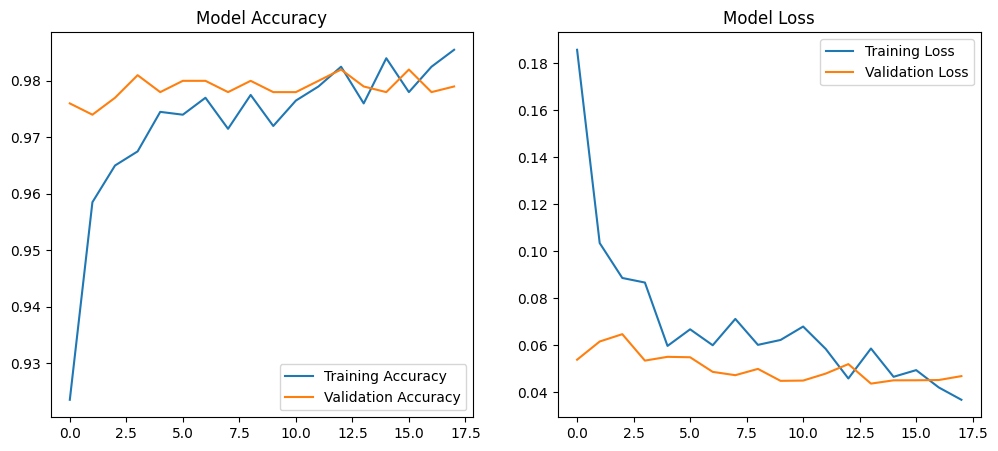

Best validation accuracy: 98.2 %


In [19]:
# Combine training histories
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']

loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Model Loss')
plt.legend()

plt.show()

print("Best validation accuracy:",
      round(max(val_acc) * 100, 2), "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 20s 15s/step
Total predictions: 50


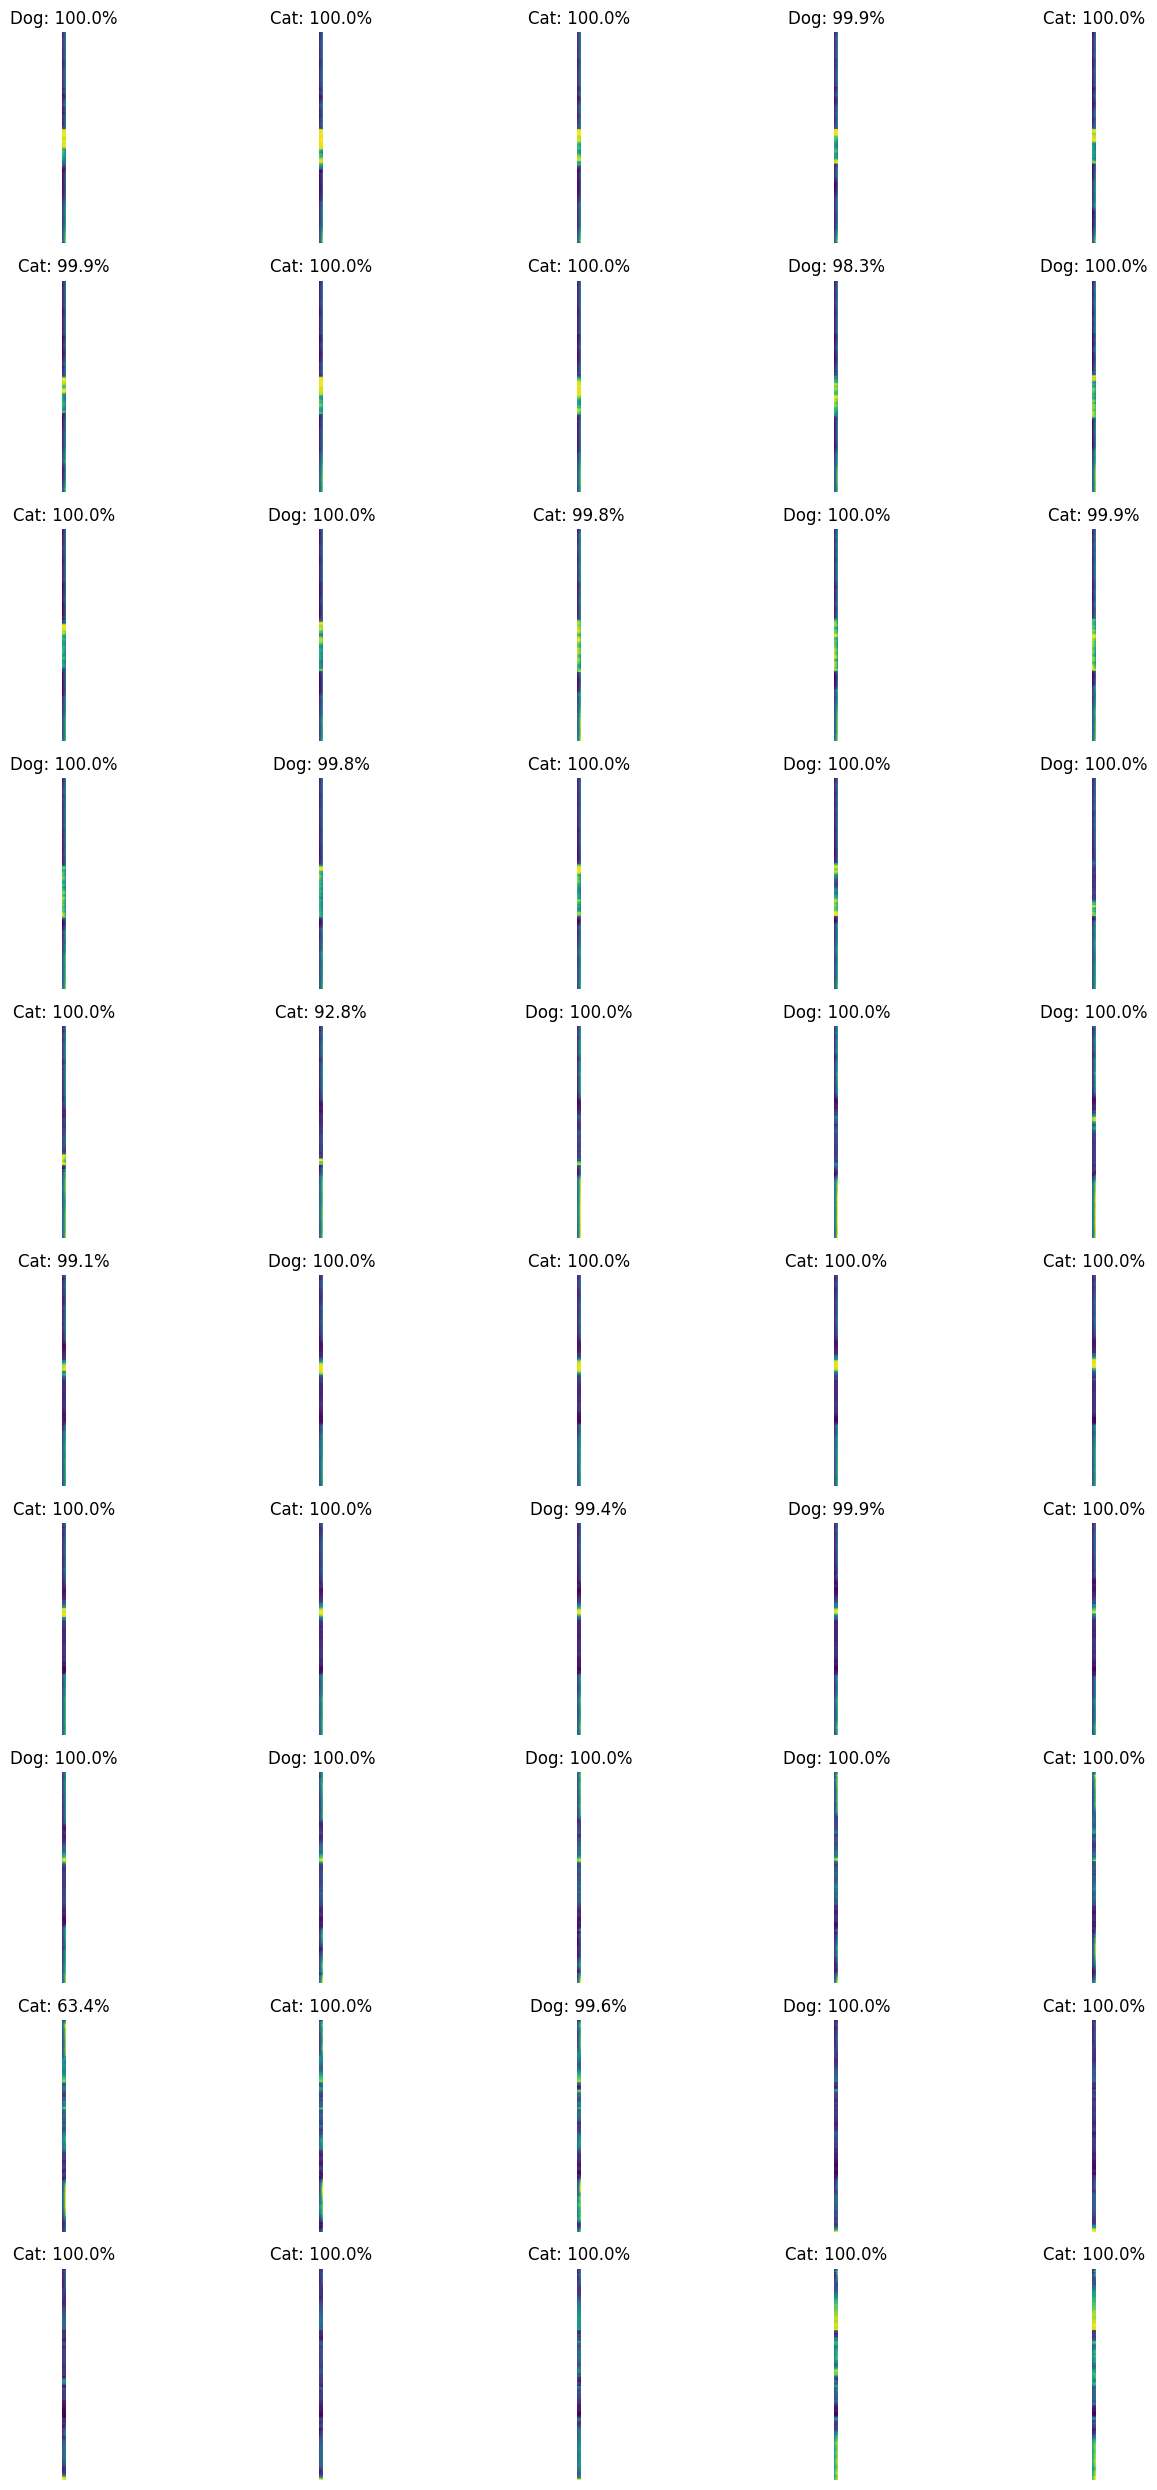

In [20]:
# Reset test generator
test_data_gen.reset()

# Load all 50 test images
test_images = np.concatenate([
    test_data_gen[i][0]
    for i in range(len(test_data_gen))
], axis=0)

# Predict cat/dog probabilities
test_data_gen.reset()

scores = model.predict(test_data_gen).flatten()

# Convert probabilities into binary predictions
probabilities = [
    1 if score >= 0.5 else 0
    for score in scores
]

print("Total predictions:", len(probabilities))

# Display all 50 images
def plotImages(images_arr, probabilities=None):

    fig, axes = plt.subplots(10, 5, figsize=(15, 25))
    axes = axes.flatten()

    for img, ax, i in zip(images_arr, axes, range(len(images_arr))):

        # Convert MobileNetV2 preprocessing back to display range
        img = (img + 1) / 2

        ax.imshow(np.clip(img, 0, 1))
        ax.axis('off')

        if probabilities is not None:
            label = "Dog" if probabilities[i] >= 0.5 else "Cat"
            confidence = probabilities[i] if label == "Dog" else 1 - probabilities[i]

            ax.set_title(
                f"{label}: {confidence * 100:.1f}%"
            )

    plt.tight_layout()
    plt.show()


plotImages(test_images, scores)

In [21]:
# Official FreeCodeCamp test answers

answers = [
    1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
    1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
    1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1,
    1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1,
    0, 0, 0, 0, 0, 0
]

correct = 0

for prediction, answer in zip(probabilities, answers):
    if prediction == answer:
        correct += 1

percentage_identified = correct / len(answers)

print(
    f"Your model correctly identified "
    f"{percentage_identified * 100:.2f}% of the images."
)

if percentage_identified > 0.63:
    print("Congratulations! You passed the challenge!")
else:
    print("You haven't passed yet. Keep improving your model!")

Your model correctly identified 96.00% of the images.
Congratulations! You passed the challenge!
